# RAG over NIST and CISA authentication guidance
**Shamak Patel · IT7075 Applied AI for Cybersecurity · Mini Project: Build a RAG System for Your Own Data**

This notebook builds a retrieval-augmented generation (RAG) system in two stages:

| Part | What happens | Data |
|---|---|---|
| 1-5 | The course pipeline with the five TODOs filled in: chunk, embed and store, retrieve, augment, measure | course documents in `course_kb/` |
| 6 | Load my documents and questions, and check every evidence phrase | `my_kb/`, `goldset.json` |
| 7 | My RAG: build the vector database, then answer all eight questions (transcript) | `my_kb/` |
| 8 | Experiments: change one setting at a time, score each, save `results.csv` and the charts | `my_kb/` |
| 9 | The settings I chose, the final transcript, and a close look at what went wrong | `my_kb/` |

**Topic:** password rules and multifactor authentication (MFA), from NIST SP 800-63B-4 and two CISA fact
sheets. Everything runs offline on the small `all-MiniLM-L6-v2` embedding model: no API key, no GPU.
If `OPENAI_API_KEY` is set, the generate step uses an LLM instead of the offline answer.

**To run:** `pip install -r requirements.txt`, then run all cells from the top. The notebook expects to run
from the `rag_project/` folder.

# Mini Project — Build a RAG System for Your Own Data
### IT7075: Applied AI for Cybersecurity · Retrieval-Augmented Generation

The first half of this notebook is the lecture pipeline with five pieces left for you to write, one per
step of the RAG recipe you saw in class:

| | Step | You write |
|---|---|---|
| **TODO 1** | chunk the documents | 3 lines |
| **TODO 2** | embed and store them in ChromaDB | 2 lines |
| **TODO 3** | retrieve the closest chunks | 3 lines |
| **TODO 4** | augment the prompt with what you retrieved | 2 lines |
| **TODO 5** | measure whether the answer was actually found | 4 lines |

Everything else is already written. Each TODO is marked like this, so you can find them by
searching for `###################`:

```
###################  TODO n — title  ###################
# what to do, and how
################
```

The five TODOs are practice on the course documents. After them, from Part 6 onward, no code is
provided: you build a RAG for data you create yourself, run your own experiments, and write it up in a
report and a video. Read `MiniProject_RAG.md` for the deliverables and the rubric.

> **Runs offline.** No API key needed. The generate step uses one if you have it, and otherwise
> prints an offline answer so the pipeline still works end to end.

## Part 1 — Chunk the documents  ·  **TODO 1**

The first few lines import what you need and load the embedding model — nothing to change there.
Then comes your first piece of code.

You cannot embed a whole document as one vector — one vector cannot represent ten topics. So you
cut each document into overlapping chunks, exactly as in Lecture 2. The **overlap** keeps a
sentence that lands on a boundary from being lost to both chunks.

> **Expected output:** `ssrf.txt -> 11 chunks`, `cybersecurity_kb.md -> 11 chunks`, **22 total**.

In [1]:
# If needed:  !pip install -q sentence-transformers chromadb pandas matplotlib openai
import json, os
import pandas as pd
import matplotlib.pyplot as plt

# Keep this notebook on the CPU. The model here is tiny (milliseconds either way),
# and this avoids the "CUDA error: no kernel image is available" failure -- or a very
# long hang while torch initialises -- on a machine whose PyTorch build does not match
# its GPU. This must run BEFORE anything imports torch.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")   # no progress-bar widgets in the saved notebook

from sentence_transformers import SentenceTransformer
import chromadb

# ---- the documents that came with the course -----------------------------
def kb_path(name):
    """The course files live in RAG/code/. In my repository they are copied to course_kb/."""
    for p in ["course_kb/" + name, "../../code/" + name, "../../../code/" + name]:
        if os.path.exists(p):
            return p
    return name

COURSE_KB = [kb_path("ssrf.txt"), kb_path("cybersecurity_kb.md")]

# the question set for those documents (Part 5) sits next to this notebook
GOLDSET_FILE = ("baseline_goldset.json" if os.path.exists("baseline_goldset.json")
                else "../baseline_goldset.json")

# ---- ONE embedding model, used for BOTH the chunks and the questions -----
embedder = SentenceTransformer("all-MiniLM-L6-v2")     # 384 numbers per text, runs locally

def embed(texts):
    return embedder.encode(texts, normalize_embeddings=True).tolist()


###################  TODO 1 — cut a document into overlapping chunks  ###################
# WHAT: finish split_into_chunks() so it returns a list of text pieces.
#
# HOW (this is the Lecture 2 chunking cell):
#   * piece  = chunk_size characters of `text`, starting at `start`, with .strip()
#              applied so you don't keep leading/trailing whitespace
#   * append the piece to `pieces`, but ONLY if it is not an empty string
#   * move `start` forward by (chunk_size - overlap) -- NOT by chunk_size,
#     because the two chunks are supposed to share `overlap` characters
#
# WATCH OUT: if you move `start` forward by chunk_size you get no overlap at all;
#            if you forget to move it, the loop never ends.
################

def split_into_chunks(text, chunk_size=600, overlap=100):
    pieces = []
    start = 0
    while start < len(text):
        piece = text[start : start + chunk_size].strip()                      # <<< TODO 1
        if piece != "":                                                       # <<< TODO 1
            pieces.append(piece)
        start = start + chunk_size - overlap                                  # <<< TODO 1
    return pieces


# ---- given: apply it to both course documents ---------------------------
def load_and_chunk(files, chunk_size=600, overlap=100):
    """Read every file, chunk it, and remember which file each chunk came from."""
    chunks, sources = [], []
    for path in files:
        text = open(path, encoding="utf-8").read()
        pieces = split_into_chunks(text, chunk_size, overlap)
        chunks += pieces
        sources += [os.path.basename(path)] * len(pieces)
        print("  %-24s -> %2d chunks" % (os.path.basename(path), len(pieces)))
    return chunks, sources

chunks, sources = load_and_chunk(COURSE_KB)
print("  TOTAL:", len(chunks), "chunks")
print("\nFirst chunk starts:", chunks[0][:70])

  ssrf.txt                 -> 11 chunks
  cybersecurity_kb.md      -> 11 chunks
  TOTAL: 22 chunks

First chunk starts: Server-Side Request Forgery Prevention Cheat Sheet
Introduction
The ob


## Part 2 — Embed and store in ChromaDB  ·  **TODO 2**

Now turn every chunk into a vector and put it in the vector database, as in Lecture 2. The
collection is created for you with `cosine` distance — Chroma's default is a different metric, and
every threshold in this notebook assumes cosine.

> **Expected output:** `Stored 22 chunks`.

In [2]:
client = chromadb.EphemeralClient()
_counter = [0]

def build_collection(chunks, sources):
    """Given: make a NEW empty collection using cosine distance, then fill it."""
    _counter[0] += 1                     # a fresh name each time, so re-running
    name = "kb_%d" % _counter[0]         # never mixes old chunks with new ones
    collection = client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})

    ###################  TODO 2 — put the chunks in the database  ###################
    # WHAT: give collection.add() the two arguments it is still missing.
    #
    # HOW (the Lecture 2 "operate ChromaDB" cell):
    #   * embeddings = the vectors for `chunks`. Use the embed() helper from
    #     Part 1 -- the SAME model must embed the chunks and, later, the question,
    #     or the distances mean nothing.
    #   * metadatas  = one small dict per chunk recording where it came from:
    #                  [{"source": s} for s in sources]
    #                  This is what lets an answer cite a file.
    ################

    collection.add(ids=["c%d" % i for i in range(len(chunks))],
                   documents=chunks,
                   embeddings=embed(chunks),                                  # <<< TODO 2
                   metadatas=[{"source": s} for s in sources])                # <<< TODO 2
    return collection


collection = build_collection(chunks, sources)
print("Stored", collection.count(), "chunks")

Stored 22 chunks


## Part 3 — Retrieve  ·  **TODO 3**

Embed the question with the same model, ask the database for the `k` closest chunks, and throw
away anything farther than `max_distance`.

That last step is the one people skip, and it matters: without it the database **always** returns
`k` chunks no matter how irrelevant, so your bot will happily answer a question your documents
never covered. An empty result is a *good* result — Part 4 turns it into "I don't know".

> **Expected output:** 4 hits for the SSRF question with distances around 0.36–0.43, and
> **0 hits** for "What is the capital of France?".

In [3]:
###################  TODO 3 — find the closest chunks  ###################
# WHAT: finish retrieve() so it returns a list of hits, closest first.
#       Each hit is a dict: {"text": ..., "distance": ..., "source": ...}
#
# HOW (the Lecture 3 retrieve cell):
#   * query the collection with the EMBEDDED question and n_results=k:
#         results = collection.query(query_embeddings=embed([question]), n_results=k)
#   * Chroma wraps its answer in a list (one entry per question, and we asked one),
#     so the pieces you want are:
#         results["documents"][0]   results["distances"][0]   results["metadatas"][0]
#   * keep a hit only when its distance <= max_distance
#
# REMEMBER: cosine distance, so SMALL = similar. 0.0 is identical, 1.0 is unrelated.
################

def retrieve(collection, question, k=4, max_distance=0.75):
    results = collection.query(query_embeddings=embed([question]), n_results=k) # <<< TODO 3

    hits = []
    for doc, dist, meta in zip(results["documents"][0],
                               results["distances"][0],
                               results["metadatas"][0]):
        if dist <= max_distance:                                              # <<< TODO 3
            hits.append({"text": doc, "distance": dist, "source": meta["source"]}) # <<< TODO 3
    return hits


# ---- given: try it on a question the documents answer, and one they don't
for q in ["Is SSRF limited to HTTP, or can other protocols be involved?",
          "What is the capital of France?"]:
    found = retrieve(collection, q)
    print("Q:", q)
    print("   hits:", len(found))
    for h in found:
        print("     distance %.3f  [%s]  %s..." % (h["distance"], h["source"],
                                                   h["text"][:60].replace("\n", " ")))
    print()

Q: Is SSRF limited to HTTP, or can other protocols be involved?
   hits: 4
     distance 0.356  [ssrf.txt]  ed, and if poorly handled, can perform specific injection at...
     distance 0.399  [ssrf.txt]  teract with the internal/external network or the machine its...
     distance 0.405  [ssrf.txt]  ed to perform an SSRF attack. Take a look at the XXE cheat s...
     distance 0.431  [ssrf.txt]  ill be based on the following information:  String containin...

Q: What is the capital of France?
   hits: 0



## Part 4 — Augment the prompt and generate  ·  **TODO 4**

Augmentation is just building a string: paste the retrieved chunks into the prompt and tell the
model to answer from them only. `generate()` and `ask()` are written for you.

> **Expected output:** the SSRF question comes back tagged `[RAG]`; the Log4Shell question comes
> back tagged `[LLM]` with no context — the honest refusal from Lecture 3.

In [4]:
SYSTEM = (
    "You are a cybersecurity assistant. Answer the question using ONLY the context below.\n"
    "Cite the source file for every claim, like [ssrf.txt]. If the answer is in the context, start "
    "your reply with [RAG]. If the context is empty or does not contain the answer, say you do not "
    "know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"
)

###################  TODO 4 — build the context block  ###################
# WHAT: finish build_context() so it turns a list of hits into ONE string.
#
# Format each hit like this, so the answer can be traced back to a file:
#
#     [1] (source: ssrf.txt)
#     <the chunk text>
#
#     [2] (source: cybersecurity_kb.md)
#     <the chunk text>
#
# HOW:
#   * loop over hits with  enumerate(hits, start=1)  so the numbering starts at 1
#   * build each block as  "[%d] (source: %s)\n%s" % (i, h["source"], h["text"])
#   * join the blocks with a BLANK LINE between them:  "\n\n".join(blocks)
#
# IMPORTANT: return "" when hits is empty. That empty string is what triggers the
#            [LLM] refusal path below -- do not return "no results" text instead.
################

def build_context(hits):
    if not hits:
        return ""
    blocks = []
    for i, h in enumerate(hits, start=1):
        blocks.append("[%d] (source: %s)\n%s" % (i, h["source"], h["text"]))  # <<< TODO 4
    return "\n\n".join(blocks)                                                # <<< TODO 4


# ---- given: generate an answer, then the whole pipeline in one function --
_USE_API = [True]      # set to False after one failure, so we don't retry a dead key

def generate(system, user):
    """Uses an LLM if one is available; otherwise quotes the context so this runs offline.

    The API call is guarded: if your key is missing, expired, or out of credit, the
    notebook prints one short note and keeps going in offline mode. Retrieval,
    scoring, and the whole tuning experiment do not need an LLM at all.
    """
    if os.getenv("OPENAI_API_KEY") and _USE_API[0]:
        try:
            from openai import OpenAI
            r = OpenAI().chat.completions.create(
                model="gpt-4o-mini", temperature=0,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}])
            return r.choices[0].message.content
        except Exception as e:
            _USE_API[0] = False
            print("   (LLM unavailable - %s. Switching to offline mode for the rest of the"
                  " notebook; nothing in this project needs an LLM.)" % type(e).__name__)

    context = system.split("# Context\n", 1)[-1]
    if context.strip() == "" or context.strip() == "(nothing found)":
        return "[LLM] I don't know -- the documents do not cover this. (offline mode)"
    return "[RAG] (offline mode) From the retrieved context:\n" + context[:300]


def ask(collection, question, k=4, max_distance=0.75, show=True):
    """The complete RAG pipeline: retrieve -> augment -> generate."""
    hits = retrieve(collection, question, k, max_distance)
    context = build_context(hits)
    system = SYSTEM.format(context=context if context else "(nothing found)")
    answer = generate(system, question)
    if show:
        print("Q:", question)
        print("   grounded?", "YES, %d chunk(s)" % len(hits) if hits else "NO, nothing retrieved")
        print("   answer:", answer[:300].replace("\n", "\n           "), "\n")
    return {"hits": hits, "answer": answer}


_ = ask(collection, "What are the two basic cases in which SSRF can happen?")
_ = ask(collection, "What CVSS score did Log4Shell receive?")     # not in the documents

Q: What are the two basic cases in which SSRF can happen?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: ssrf.txt)
           ed to perform an SSRF attack. Take a look at the XXE cheat sheet to learn how to prevent exposure to XXE.
           Cases
           Depending on the application’s functionality and requirements, there are two basic cases in which SSRF can happen:
           
            

Q: What CVSS score did Log4Shell receive?
   grounded? NO, nothing retrieved
   answer: [LLM] I don't know -- the documents do not cover this. (offline mode) 



## Part 5 — Measure it  ·  **TODO 5**

To say one setting is better than another you need a number. `baseline_goldset.json` has **8
questions** about the course documents: **6 the documents answer** (each with the exact `evidence`
wording that proves it) and **2 they do not**.

Two counts, and that is all:

- **found** — of the 6 answerable questions, how many retrieved a chunk containing the evidence?
- **refused** — of the 2 unanswerable ones, how many correctly retrieved *nothing*?

> **Expected output at the Lecture 3 settings (k=4, threshold 0.75): found 6/6, refused 2/2.**

In [5]:
GOLDSET = json.load(open(GOLDSET_FILE))["questions"]
print("Loaded", len(GOLDSET), "questions\n")

###################  TODO 5 — score one configuration  ###################
# WHAT: finish score() so it counts `found` and `refused`.
#
# For each question q in the gold set, retrieve() is already called for you.
# Then:
#   * if q["answerable"] is True:
#       - the question counts as FOUND when ANY retrieved hit contains ANY of the
#         phrases in q["evidence"]. Compare in lower case, because the documents
#         are not consistently capitalised:
#             phrase.lower() in hit["text"].lower()
#       - a small helper, found_evidence(hits, q["evidence"]), is started for you
#   * if q["answerable"] is False:
#       - it counts as REFUSED when len(hits) == 0 -- nothing was retrieved
#
# WHY only these two numbers: `found` tells you whether the right text reached the
# model, and `refused` tells you whether the bot keeps quiet when it should. A
# setting that improves one while wrecking the other is not an improvement.
################

def found_evidence(hits, evidence):
    for h in hits:
        for phrase in evidence:
            if phrase.lower() in h["text"].lower():                           # <<< TODO 5
                return True
    return False


def score(collection, goldset, k=4, max_distance=0.75):
    found, refused = 0, 0
    for q in goldset:
        hits = retrieve(collection, q["question"], k, max_distance)
        if q["answerable"]:
            if found_evidence(hits, q["evidence"]):                           # <<< TODO 5
                found += 1                                                    # <<< TODO 5
        else:
            if len(hits) == 0:                                                # <<< TODO 5
                refused += 1
    return found, refused


n_answerable = sum(q["answerable"] for q in GOLDSET)
n_unanswerable = len(GOLDSET) - n_answerable

found, refused = score(collection, GOLDSET)
print("found   %d/%d answerable questions" % (found, n_answerable))
print("refused %d/%d unanswerable questions" % (refused, n_unanswerable))

Loaded 8 questions

found   6/6 answerable questions
refused 2/2 unanswerable questions


## Part 6: from here on, the code is yours

Everything above ran on the course documents, and it was practice: the same pipeline you saw in the
lectures, one piece at a time. The rest of this notebook is a RAG for your own data, and no code is
provided for it. Reuse anything you wrote in Parts 1 to 5, adapt code from the lecture notebooks, or
write something different. What matters is that it works on your data and that you can explain it.

Add cells below that do all of the following:

1. Load your documents from `my_kb/` and report how many documents and how many characters you have.
2. Load your questions from `goldset.json`, and check that every evidence phrase really appears in your
   documents exactly as written. If one does not, your own results will report a miss that is not real.
3. Chunk, embed, and store your documents.
4. Answer your questions and print the transcript, including at least one question your documents cannot
   answer, so that the refusal is visible.
5. Run your experiments. Change one setting at a time, such as chunk size, the number of chunks
   retrieved, or the distance threshold, score each configuration against your gold set, collect the
   results in a table, and save it as `results.csv`.
6. Draw at least one chart from your results and save it as a `.png`.

My cells follow.

> When you are finished, run the whole notebook top to bottom and save it with the outputs showing,
> then commit it to your private GitHub repository along with `my_kb/`, `goldset.json`, `results.csv`,
> and your chart. See `MiniProject_RAG.md` section 7.1 for the folder structure.

## Part 6: My data — passwords and MFA guidance from NIST and CISA

I chose authentication because it is the control every other one depends on, and because the official guidance
changed in ways people still get wrong (NIST now says *not* to force periodic password changes). The guidance
is also precise, so every question has a checkable answer.

| File in `my_kb/` | Source | What it covers |
|---|---|---|
| `nist_password_rules.md` | NIST SP 800-63B-4, Sec. 3.1.1 | length, composition, rotation, hints and security questions |
| `nist_password_blocklist_and_storage.md` | NIST SP 800-63B-4, Sec. 3.1.1.2 | blocklists, password managers, salting and hashing |
| `nist_rate_limiting_and_aal.md` | NIST SP 800-63B-4, Sec. 3.2.2 and AAL summary | failed-attempt limits, assurance levels 1-3 |
| `cisa_phishing_resistant_mfa.md` | CISA fact sheet, Oct 2022 | threats to MFA, MFA forms ranked, FIDO/WebAuthn |
| `cisa_number_matching.md` | CISA fact sheet, Oct 2022 | push bombing (MFA fatigue) and number matching |

All five are excerpts of US government publications, which are not subject to copyright; `my_kb/SOURCES.md`
gives the links and says exactly what was cut. Paragraphs are kept on one line each, so a line break can never
split an evidence phrase.

**My eight questions** (`goldset.json`): six the documents answer, one per topic, phrased the way a person would
ask rather than copied from the text; one clearly off-topic question (Q7, cookies); and one that *sounds* right
but is not answered (Q8: how long a session may last before reauthentication). NIST does answer Q8, in Sections
2.1.3-2.3.3 and 5.2 of the same publication, but I left those sections out on purpose. That makes Q8 a fair test:
the documents are full of words like *NIST*, *authenticator* and *AAL*, so retrieval will find chunks that look
relevant, and a system that answers anyway is making the answer up.

In [6]:
###################  YOUR DATA — load and check  ###################
# Load my documents from my_kb/ and my questions from goldset.json, report the
# document count and total characters, and check every evidence phrase.
################
import glob, re, textwrap
import numpy as np

MY_KB_DIR = "my_kb"
MY_FILES = sorted(f for f in glob.glob(os.path.join(MY_KB_DIR, "*.md"))
                  if os.path.basename(f) != "SOURCES.md")      # SOURCES.md lists citations, it is not knowledge
my_texts = {os.path.basename(f): open(f, encoding="utf-8").read() for f in MY_FILES}

print("Documents in %s/: %d" % (MY_KB_DIR, len(my_texts)))
for name, text in my_texts.items():
    print("  %-40s %6d characters" % (name, len(text)))
print("  %-40s %6d characters" % ("TOTAL", sum(len(t) for t in my_texts.values())))

MY_GOLDSET = json.load(open("goldset.json"))["questions"]
n_mine_ans = sum(q["answerable"] for q in MY_GOLDSET)
n_mine_unans = len(MY_GOLDSET) - n_mine_ans
print("\nQuestions in goldset.json: %d (%d answerable, %d unanswerable)"
      % (len(MY_GOLDSET), n_mine_ans, n_mine_unans))

# Each evidence phrase must be in its source file word-for-word, on one line, and
# short (<= 80 characters) so a chunk boundary is unlikely to cut it in half.
# Otherwise the score would report a miss that is not real.
print("\nEvidence check:")
problems = 0
for q in MY_GOLDSET:
    if not q["answerable"]:
        print("  %-3s --    no evidence (should be refused): %s" % (q["qid"], q["question"]))
        continue
    text = my_texts.get(q["source"], "")
    for phrase in q["evidence"]:
        ok = (phrase in text
              and any(phrase in line for line in text.splitlines())
              and len(phrase) <= 80)
        problems += not ok
        print("  %-3s %-4s  %2d chars in %-38s %s" % (q["qid"], "OK" if ok else "FAIL",
                                                     len(phrase), q["source"], phrase))
print("\nAll evidence phrases verified." if problems == 0 else
      "\n%d PROBLEM(S): fix goldset.json before trusting any score below." % problems)

Documents in my_kb/: 5
  cisa_number_matching.md                    2403 characters
  cisa_phishing_resistant_mfa.md             2798 characters
  nist_password_blocklist_and_storage.md     2254 characters
  nist_password_rules.md                     2231 characters
  nist_rate_limiting_and_aal.md              2368 characters
  TOTAL                                     12054 characters

Questions in goldset.json: 8 (6 answerable, 2 unanswerable)

Evidence check:
  Q1  OK    36 chars in nist_password_rules.md                 a minimum of 15 characters in length
  Q2  OK    62 chars in nist_password_rules.md                 SHALL NOT require subscribers to change passwords periodically
  Q3  OK    77 chars in nist_password_blocklist_and_storage.md Passwords SHALL be salted and hashed using a suitable password hashing scheme
  Q4  OK    48 chars in nist_rate_limiting_and_aal.md          no more than 100 by disabling that authenticator
  Q5  OK    76 chars in cisa_phishing_resistant_mfa.md

## Part 7: My RAG — build it and ask my questions

The same three RAG steps as the lectures, reusing the functions written in Parts 1 to 5:

1. **Retrieve.** The documents are cut into 600-character chunks with 100 characters of overlap
   (`split_into_chunks`, TODO 1), and each chunk is embedded with `all-MiniLM-L6-v2` and stored in ChromaDB with
   its source file (`build_collection`, TODO 2). A question is embedded with the *same* model, and the database
   returns the `k = 4` closest chunks; any farther than cosine distance `0.75` are dropped (`retrieve`, TODO 3).
2. **Augment.** The surviving chunks are numbered, tagged with their file, and pasted into a system prompt that
   says *answer only from this context, cite the file, and say you don't know if it isn't there*
   (`build_context`, TODO 4, and `MY_SYSTEM` below).
3. **Generate.** If nothing was retrieved, the answer is a refusal and no model is called at all. Otherwise, with
   an `OPENAI_API_KEY` the prompt goes to an LLM; without one, `offline_answer` stands in for the LLM by quoting
   the three sentences from the retrieved chunks that are closest in meaning to the question, each with its
   source file. The starter's offline mode printed the first 300 characters of the context; quoting the best sentences
   gives an answer you can actually read and check.

These first runs use the course defaults (chunk 600, overlap 100, k 4, threshold 0.75). Part 8 tests whether
they suit my documents.

In [7]:
###################  YOUR RAG — build  ###################
# Chunk, embed and store my documents with the functions from Parts 1 and 2.
################
my_chunks, my_sources = load_and_chunk(MY_FILES, chunk_size=600, overlap=100)    # TODO 1
print("  TOTAL:", len(my_chunks), "chunks")
my_collection = build_collection(my_chunks, my_sources)                         # TODO 2
print("Stored", my_collection.count(), "chunks in ChromaDB (cosine distance)")

# What the vector database holds for each chunk: the text, its vector, and where it came from.
peek = my_collection.get(ids=["c0"], include=["documents", "embeddings", "metadatas"])
print("\nOne stored chunk (id c0):")
print("  metadata:", peek["metadatas"][0])
print("  vector:   %d numbers, starting %s" % (len(peek["embeddings"][0]),
                                               np.round(peek["embeddings"][0][:5], 3)))
print("  text:    ", peek["documents"][0][:150].replace("\n", " "), "...")

  cisa_number_matching.md  ->  5 chunks
  cisa_phishing_resistant_mfa.md ->  6 chunks
  nist_password_blocklist_and_storage.md ->  5 chunks
  nist_password_rules.md   ->  5 chunks
  nist_rate_limiting_and_aal.md ->  5 chunks
  TOTAL: 26 chunks


Stored 26 chunks in ChromaDB (cosine distance)

One stored chunk (id c0):
  metadata: {'source': 'cisa_number_matching.md'}
  vector:   384 numbers, starting [-0.076 -0.024 -0.025 -0.033  0.064]
  text:     # CISA Fact Sheet: Implementing Number Matching in MFA Applications (October 2022)  ## Overview  Mobile push-notification-based MFA is a form of appli ...


In [8]:
###################  YOUR RAG — augment and generate  ###################
MY_SYSTEM = (
    "You are an identity-security assistant. Answer the question using ONLY the context below, "
    "which comes from NIST SP 800-63B-4 and CISA fact sheets.\n"
    "Cite the source file for every claim, like [nist_password_rules.md]. If the answer is in the "
    "context, start your reply with [RAG]. If the context is empty or does not contain the answer, "
    "say you do not know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"
)


def split_sentences(text):
    """Split text into sentences and list items. Headings are titles, not answers, so they are
    dropped, as are list markers and fragments too short to say anything."""
    lines = [l for l in text.split("\n") if not l.lstrip().startswith("#")]
    parts = re.split(r"(?<!e\.g\.)(?<!i\.e\.)(?<!Sec\.)(?<=[.!?])\s+|\n+", "\n".join(lines))
    parts = [re.sub(r"^[\-*\d.\s]+", "", p).strip() for p in parts]
    return [p for p in parts if len(p) > 30]


def sentences_around(hit):
    """The whole sentences a chunk covers. Chunks are cut at a fixed character count, so the
    first and last sentence are usually cut in half; widen the chunk to the start and end of
    the lines it touches (every paragraph and list item in my_kb/ is one line)."""
    doc = my_texts[hit["source"]]
    start = doc.find(hit["text"])
    end = start + len(hit["text"])
    while start > 0 and doc[start - 1] != "\n":
        start -= 1
    while end < len(doc) and doc[end] != "\n":
        end += 1
    return split_sentences(doc[start:end])


def offline_answer(question, hits, n=3):
    """Generation without an LLM: quote the n sentences from the retrieved chunks that are
    closest in meaning to the question, each with the file it came from."""
    candidates = {}
    for h in hits:
        for s in sentences_around(h):
            candidates.setdefault(s, h["source"])     # overlapping chunks repeat sentences; keep one
    sentences = list(candidates)
    similarity = np.array(embed(sentences)) @ np.array(embed([question])[0])   # cosine similarity
    best = np.argsort(-similarity)[:n]
    return "[RAG] (offline) " + " ".join("%s [%s]" % (sentences[i], candidates[sentences[i]])
                                         for i in best)


def my_ask(collection, question, k=4, max_distance=0.75):
    """The whole pipeline for my documents: retrieve -> augment -> generate."""
    hits = retrieve(collection, question, k, max_distance)                 # 1. retrieve (TODO 3)
    context = build_context(hits)                                           # 2. augment  (TODO 4)
    system = MY_SYSTEM.format(context=context if context else "(nothing found)")
    if not hits:                                                            # 3. generate
        answer = "[LLM] I don't know -- my documents do not cover this."
    elif os.getenv("OPENAI_API_KEY") and _USE_API[0]:
        answer = generate(system, question)                                 #    an LLM, if a key is set
    else:
        answer = offline_answer(question, hits)                             #    otherwise quote the best sentences
    return {"hits": hits, "answer": answer, "prompt": system}


# The augmented prompt for Q1, exactly as an LLM would receive it.
r = my_ask(my_collection, MY_GOLDSET[0]["question"])
print("USER:  ", MY_GOLDSET[0]["question"])
print("SYSTEM (first 1,000 characters):\n")
print(r["prompt"][:1000], "...")

USER:   How long does a password have to be if it is the only thing a user types to log in?
SYSTEM (first 1,000 characters):

You are an identity-security assistant. Answer the question using ONLY the context below, which comes from NIST SP 800-63B-4 and CISA fact sheets.
Cite the source file for every claim, like [nist_password_rules.md]. If the answer is in the context, start your reply with [RAG]. If the context is empty or does not contain the answer, say you do not know and start with [LLM] -- do not answer from memory.

# Context
[1] (source: nist_password_rules.md)
words that are used as a single-factor authentication mechanism to be a minimum of 15 characters in length. Verifiers and CSPs MAY allow passwords that are only used as part of multi-factor authentication processes to be shorter but SHALL require them to be a minimum of eight characters in length.
2. Verifiers and CSPs SHOULD permit a maximum password length of at least 64 characters.
5. Verifiers and CSPs SHALL NOT i

In [9]:
###################  YOUR RAG — transcript  ###################
# Answer all eight questions and judge each one against goldset.json.
################
def show(q, result):
    print("%s  %s" % (q["qid"], q["question"]))
    print("    expected:", ("answerable, from " + q["source"]) if q["answerable"]
          else "NOT in my documents, so it should be refused")
    for h in result["hits"]:
        print("    retrieved  d=%.3f  [%s]  %s..." % (h["distance"], h["source"],
                                                    h["text"][:50].replace("\n", " ")))
    if not result["hits"]:
        print("    retrieved  nothing within the distance threshold")
    print("    answer:  ", textwrap.fill(result["answer"], 105, subsequent_indent=" " * 15))
    if q["answerable"]:
        ok = found_evidence(result["hits"], q["evidence"])
        verdict = "FOUND the evidence" if ok else "MISSED the evidence"
    else:
        ok = not result["hits"]
        verdict = "REFUSED, correctly" if ok else "ANSWERED ANYWAY from chunks that do not contain the answer"
    print("    verdict:  %s %s\n" % ("OK   " if ok else "WRONG", verdict))


print("Settings: chunk_size=600, overlap=100, k=4, max_distance=0.75 (the course defaults)\n")
for q in MY_GOLDSET:
    show(q, my_ask(my_collection, q["question"], k=4, max_distance=0.75))

found, refused = score(my_collection, MY_GOLDSET, k=4, max_distance=0.75)        # TODO 5
print("SCORE at the course defaults: found %d/%d, refused %d/%d"
      % (found, n_mine_ans, refused, n_mine_unans))

Settings: chunk_size=600, overlap=100, k=4, max_distance=0.75 (the course defaults)

Q1  How long does a password have to be if it is the only thing a user types to log in?
    expected: answerable, from nist_password_rules.md
    retrieved  d=0.499  [nist_password_rules.md]  words that are used as a single-factor authenticat...
    retrieved  d=0.529  [nist_password_blocklist_and_storage.md]  least 32 bits in length and chosen to minimize sal...
    retrieved  d=0.531  [nist_password_rules.md]  # NIST SP 800-63B-4: Passwords (Section 3.1.1)  A ...
    retrieved  d=0.549  [nist_password_rules.md]  e name of your first pet?”) or security questions ...
    answer:   [RAG] (offline) Verifiers and CSPs SHOULD permit a maximum password length of at least 64 characters.
               [nist_password_rules.md] Other composition requirements for passwords SHALL NOT be
               imposed. [nist_password_rules.md] Verifiers and CSPs SHALL require passwords that are used
               as a s

Q3  How should a website store user passwords so they stay safe if the database is stolen?
    expected: answerable, from nist_password_blocklist_and_storage.md
    retrieved  d=0.539  [nist_password_blocklist_and_storage.md]  tors.  ## Storing passwords  Verifiers SHALL store...
    retrieved  d=0.550  [nist_password_rules.md]  # NIST SP 800-63B-4: Passwords (Section 3.1.1)  A ...
    retrieved  d=0.639  [nist_password_rules.md]  e name of your first pet?”) or security questions ...
    retrieved  d=0.641  [nist_password_rules.md]  types) for passwords. 6. Verifiers and CSPs SHALL ...
    answer:   [RAG] (offline) Passwords must be of sufficient effective strength and secrecy that it would be
               impractical for an attacker to guess or otherwise discover the correct secret value.
               [nist_password_rules.md] A password is “something you know.” Passwords are not phishing-
               resistant. [nist_password_rules.md] Passwords SHALL be salted and hashed using

Q4  How many failed login attempts in a row are allowed before the authenticator must be disabled?
    expected: answerable, from nist_rate_limiting_and_aal.md
    retrieved  d=0.397  [nist_rate_limiting_and_aal.md]  g that authenticator.  The limit of 100 attempts i...
    retrieved  d=0.405  [nist_rate_limiting_and_aal.md]  # NIST SP 800-63B-4: Rate Limiting (Section 3.2.2)...
    retrieved  d=0.473  [nist_rate_limiting_and_aal.md]  imant to complete a bot detection and mitigation c...
    retrieved  d=0.532  [cisa_number_matching.md]  Mitigation  Number matching is a setting that forc...
    answer:   [RAG] (offline) Unless otherwise specified in the description of a given authenticator, the verifier
               SHALL limit consecutive failed authentication attempts using a specific authenticator on a
               single subscriber account to no more than 100 by disabling that authenticator.
               [nist_rate_limiting_and_aal.md] Requiring the claimant to wait after a f

Q8  How long can a session stay active before NIST requires the user to reauthenticate?
    expected: NOT in my documents, so it should be refused
    retrieved  d=0.600  [nist_rate_limiting_and_aal.md]  # NIST SP 800-63B-4: Rate Limiting (Section 3.2.2)...
    retrieved  d=0.659  [nist_rate_limiting_and_aal.md]  imant to complete a bot detection and mitigation c...
    retrieved  d=0.682  [nist_rate_limiting_and_aal.md]  g that authenticator.  The limit of 100 attempts i...
    retrieved  d=0.715  [nist_password_rules.md]  # NIST SP 800-63B-4: Passwords (Section 3.1.1)  A ...
    answer:   [RAG] (offline) Unless otherwise specified in the description of a given authenticator, the verifier
               SHALL limit consecutive failed authentication attempts using a specific authenticator on a
               single subscriber account to no more than 100 by disabling that authenticator.
               [nist_rate_limiting_and_aal.md] Requiring the claimant to wait after a failed attempt 

SCORE at the course defaults: found 6/6, refused 1/2


## Part 8: Experiments — one setting at a time

**Method.** Start from the course defaults (chunk 600, overlap 100, k 4, threshold 0.75) and change exactly one
setting at a time, scoring every configuration against my eight questions with `score()` from TODO 5:

- **found**: of the 6 answerable questions, how many retrieved a chunk containing the evidence phrase;
- **refused**: of the 2 unanswerable questions, how many retrieved nothing.

Each row also records *which* questions failed, and two distances that explain the threshold:

- `worst_answer_distance`: for each answerable question, the distance of the closest chunk (within the top k)
  that contains its evidence; this is the largest of the six. The threshold must be **at least** this
  to find all six answers.
- `closest_trap_distance`: the smallest distance from either unanswerable question to *any* chunk. The threshold
  must be **below** this to refuse both.

If `worst_answer_distance < closest_trap_distance`, some threshold gets a perfect 8/8, and the gap between the two
is the safety margin. If the gap is negative, no threshold can get 8/8 at that chunking.

In [10]:
###################  YOUR EXPERIMENTS  ###################
# Change one setting at a time, score each configuration against my gold set,
# collect the rows into a table, and save it as results.csv.
################
BASELINE = {"chunk_size": 600, "overlap": 100, "k": 4, "max_distance": 0.75}
SWEEPS = {
    "max_distance": [0.40, 0.45, 0.50, 0.525, 0.55, 0.575, 0.60, 0.625, 0.65, 0.70, 0.75, 0.80, 0.90],
    "k":            [1, 2, 3, 4, 5, 6, 8],
    "chunk_size":   [200, 300, 400, 500, 600, 800, 1000, 1500],
    "overlap":      [0, 50, 100, 150, 200],
}

_collections = {}
def collection_for(chunk_size, overlap):
    """Chunk, embed and store once per (chunk_size, overlap); k and the threshold reuse it."""
    key = (chunk_size, overlap)
    if key not in _collections:
        chunks, sources = [], []
        for name, text in my_texts.items():
            pieces = split_into_chunks(text, chunk_size, overlap)                # TODO 1
            chunks += pieces
            sources += [name] * len(pieces)
        _collections[key] = build_collection(chunks, sources)                    # TODO 2
    return _collections[key]


def evaluate(chunk_size, overlap, k, max_distance):
    """Score one configuration on my gold set and record which questions failed and why."""
    col = collection_for(chunk_size, overlap)
    found, refused = score(col, MY_GOLDSET, k, max_distance)                     # TODO 5
    missed, not_refused, answer_d, trap_d = [], [], [], []
    for q in MY_GOLDSET:
        top_k = retrieve(col, q["question"], k, max_distance=2.0)              # top k, no threshold
        kept = [h for h in top_k if h["distance"] <= max_distance]
        if q["answerable"]:
            ev = [h["distance"] for h in top_k if found_evidence([h], q["evidence"])]
            answer_d.append(min(ev) if ev else np.inf)       # inf: evidence not in the top k at all
            if not found_evidence(kept, q["evidence"]):
                missed.append(q["qid"])
        else:
            trap_d.append(top_k[0]["distance"])
            if kept:
                not_refused.append(q["qid"])
    assert len(missed) == n_mine_ans - found and len(not_refused) == n_mine_unans - refused
    return {"chunk_size": chunk_size, "overlap": overlap, "k": k, "max_distance": max_distance,
            "n_chunks": col.count(), "found": found, "refused": refused,
            "correct_of_8": found + refused,
            "missed": " ".join(missed), "not_refused": " ".join(not_refused),
            "worst_answer_distance": round(max(answer_d), 3),
            "closest_trap_distance": round(min(trap_d), 3)}


rows = []
for setting, values in SWEEPS.items():
    for v in values:
        cfg = dict(BASELINE, **{setting: v})
        rows.append({"experiment": setting, **evaluate(**cfg), "is_default": cfg == BASELINE})
results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)
print("Saved results.csv: %d configurations (%d distinct collections built)\n"
      % (len(results), len(_collections)))

COLS = ["chunk_size", "overlap", "k", "max_distance", "n_chunks", "found", "refused",
        "missed", "not_refused", "worst_answer_distance", "closest_trap_distance"]
for setting in SWEEPS:
    print("=== varying %s (others at the defaults) ===" % setting)
    print(results[results.experiment == setting][COLS].to_string(index=False), "\n")

Saved results.csv: 33 configurations (12 distinct collections built)

=== varying max_distance (others at the defaults) ===
 chunk_size  overlap  k  max_distance  n_chunks  found  refused      missed not_refused  worst_answer_distance  closest_trap_distance
        600      100  4         0.400        26      2        2 Q1 Q2 Q3 Q4                              0.555                    0.6
        600      100  4         0.450        26      3        2    Q1 Q2 Q3                              0.555                    0.6
        600      100  4         0.500        26      4        2       Q2 Q3                              0.555                    0.6
        600      100  4         0.525        26      4        2       Q2 Q3                              0.555                    0.6
        600      100  4         0.550        26      5        2          Q2                              0.555                    0.6
        600      100  4         0.575        26      6        2         

### Chart your results

Each bar is one configuration, split into the answers found (blue, out of 6) and the refusals held (orange, out
of 2). A full-height bar is a perfect 8/8. The bar outlined in black is the course default. A setting that makes
the blue grow while the orange shrinks has not improved anything: the system has started guessing.

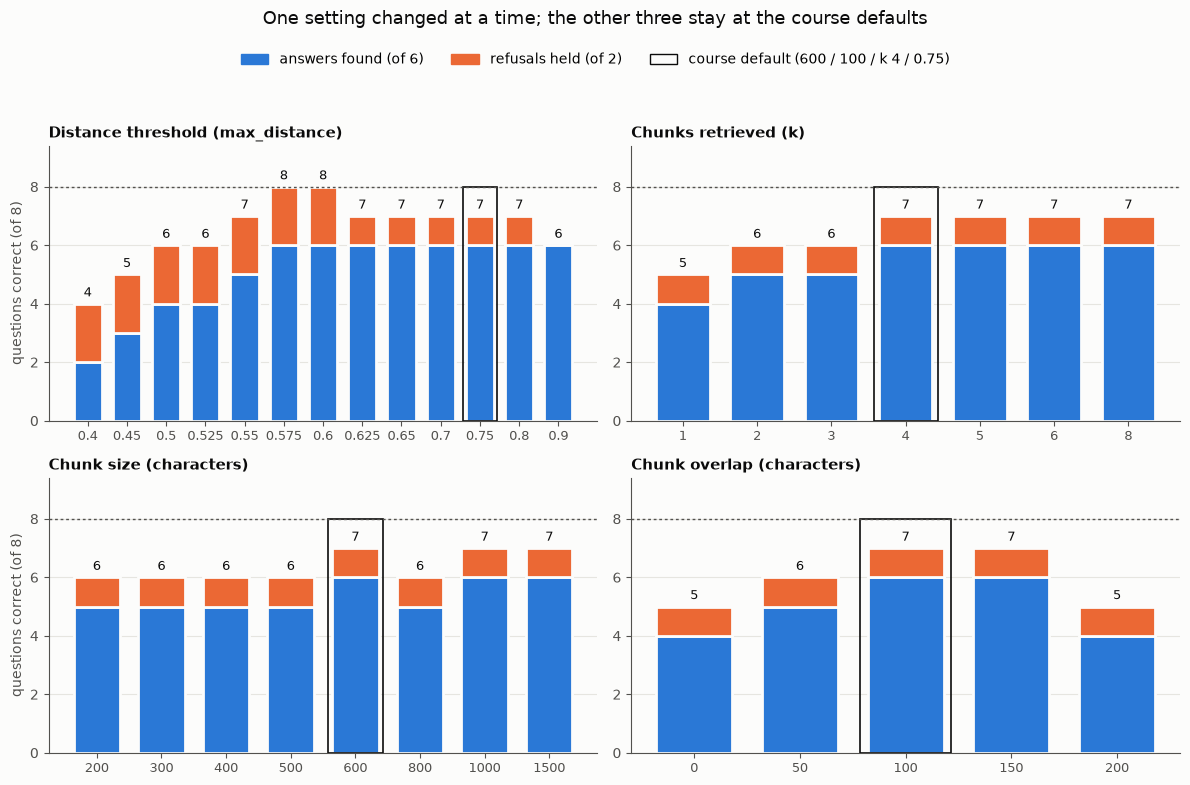

In [11]:
###################  YOUR CHART  ###################
# Draw at least one chart from the results and save it as a .png.
################
from matplotlib.patches import Patch

BLUE, ORANGE = "#2a78d6", "#eb6834"              # found, refused: a colour-blind-safe pair
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED})

TITLES = {"max_distance": "Distance threshold (max_distance)", "k": "Chunks retrieved (k)",
          "chunk_size": "Chunk size (characters)", "overlap": "Chunk overlap (characters)"}

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), facecolor=SURFACE)
for ax, setting in zip(axes.flat, SWEEPS):
    d = results[results.experiment == setting].sort_values(setting).reset_index(drop=True)
    x = np.arange(len(d))
    ax.set_facecolor(SURFACE)
    ax.bar(x, d.found, width=0.72, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.bar(x, d.refused, bottom=d.found, width=0.72, color=ORANGE, edgecolor=SURFACE, linewidth=2)
    for i, row in d.iterrows():
        ax.text(i, row.correct_of_8 + 0.15, "%d" % row.correct_of_8, ha="center", va="bottom",
                fontsize=9, color=INK)
        if row.is_default:
            ax.bar(i, 8.0, width=0.86, fill=False, edgecolor=INK, linewidth=1.2)
    ax.axhline(8, color=MUTED, lw=1, ls=(0, (2, 2)))
    ax.set_xticks(x)
    ax.set_xticklabels([("%g" % v) for v in d[setting]], fontsize=9)
    ax.set_ylim(0, 9.4)
    ax.set_yticks(range(0, 9, 2))
    ax.set_title(TITLES[setting], loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0, 0].set_ylabel("questions correct (of 8)")
axes[1, 0].set_ylabel("questions correct (of 8)")
fig.legend(handles=[Patch(color=BLUE, label="answers found (of 6)"),
                    Patch(color=ORANGE, label="refusals held (of 2)"),
                    Patch(fill=False, edgecolor=INK, label="course default (600 / 100 / k 4 / 0.75)")],
           loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("One setting changed at a time; the other three stay at the course defaults",
             y=1.04, color=INK, fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("figure.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.show()

The bar chart shows *what* happened; the next chart shows *why*. For every question it plots the cosine distance
of the chunk that matters, using the default chunking (600/100): for an answerable question, the closest chunk
that contains its evidence (blue); for an unanswerable one, the closest chunk of any kind (orange). Grey dots are
the other chunks in the top 8. A threshold finds an answer when the blue dot is to its left, and refuses a
question when the orange dot is to its right.

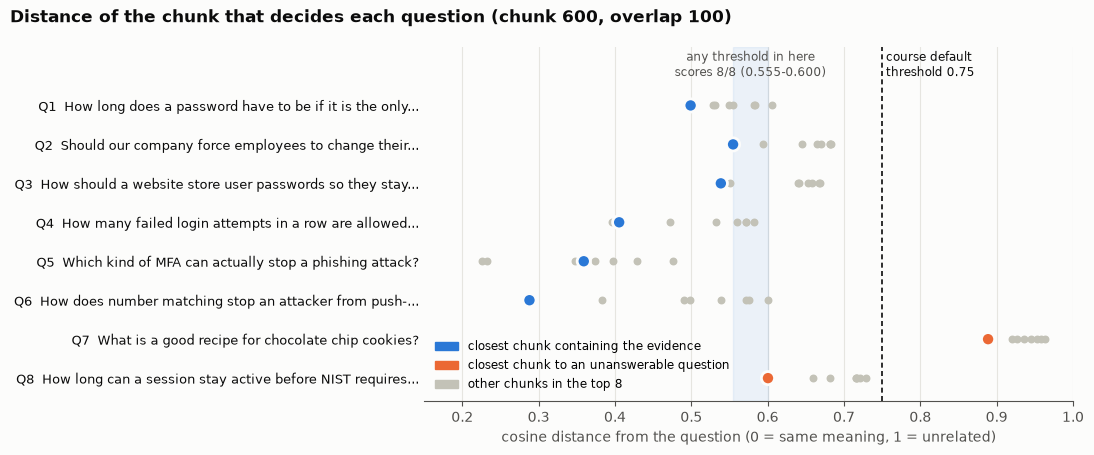

Largest evidence distance 0.555 (must be <= threshold); closest unanswerable 0.600 (must be > threshold)


In [12]:
###################  YOUR CHART (2): why the threshold behaves as it does  ###################
col = collection_for(600, 100)
labels, key_d, colours, others = [], [], [], []
for q in MY_GOLDSET:
    top = retrieve(col, q["question"], k=8, max_distance=2.0)
    if q["answerable"]:
        ev = [h["distance"] for h in top if found_evidence([h], q["evidence"])]
        key_d.append(min(ev) if ev else np.nan)
        colours.append(BLUE)
    else:
        key_d.append(top[0]["distance"])
        colours.append(ORANGE)
    others.append([h["distance"] for h in top])
    labels.append("%s  %s" % (q["qid"], textwrap.shorten(q["question"], 58, placeholder="...")))

need = np.nanmax([d for d, c in zip(key_d, colours) if c == BLUE])
trap = min(d for d, c in zip(key_d, colours) if c == ORANGE)

fig, ax = plt.subplots(figsize=(11, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
y = np.arange(len(labels))[::-1]
for yi, ds in zip(y, others):
    ax.scatter(ds, [yi] * len(ds), s=22, color="#c3c2b7", zorder=2)
ax.scatter(key_d, y, s=90, color=colours, edgecolor=SURFACE, linewidth=2, zorder=3)
if need < trap:
    ax.axvspan(need, trap, color=BLUE, alpha=0.08, zorder=1)
    ax.text((need + trap) / 2, len(labels) - 0.35, "any threshold in here\nscores 8/8 (%.3f-%.3f)"
            % (need, trap), ha="center", va="bottom", fontsize=8.5, color=MUTED)
ax.axvline(0.75, color=INK, lw=1.2, ls=(0, (3, 2)), zorder=1)
ax.text(0.755, len(labels) - 0.35, "course default\nthreshold 0.75", fontsize=8.5, color=INK,
        ha="left", va="bottom")
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=9, color=INK)
ax.set_xlim(0.15, 1.0)
ax.set_ylim(-0.6, len(labels) + 0.5)
ax.set_xlabel("cosine distance from the question (0 = same meaning, 1 = unrelated)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.suptitle("Distance of the chunk that decides each question (chunk 600, overlap 100)",
             x=0.01, ha="left", color=INK, fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color=BLUE, label="closest chunk containing the evidence"),
                   Patch(color=ORANGE, label="closest chunk to an unanswerable question"),
                   Patch(color="#c3c2b7", label="other chunks in the top 8")],
          loc="lower left", fontsize=8.5, frameon=False)
fig.tight_layout()
fig.savefig("figure_distances.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print("Largest evidence distance %.3f (must be <= threshold); closest unanswerable %.3f (must be > threshold)"
      % (need, trap))

## Part 9: The settings I chose, and what went wrong

**The setting that mattered most is the distance threshold.** Moving it alone takes the score from 4/8 (at 0.40)
to 8/8 (at 0.575-0.60) and back down to 6/8 (at 0.90). It is also the only setting that changes refusals at all:
at the default threshold of 0.75, no value of k, chunk size or overlap stopped Q8 from being answered. The other
settings mostly decide whether the evidence makes it into the top k in the first place.

**My settings: chunk 600, overlap 100, k 4, threshold 0.575.**

- **Threshold 0.575.** At this chunking the farthest evidence chunk an answerable question needs is at 0.555, and
  the closest chunk to an unanswerable question is at 0.600. Any threshold in between scores 8/8; 0.575 is the
  middle of that window. The course default of 0.75 is well past it, which is why Q8 got through.
- **k = 4.** For Q5 the chunk with the FIDO/WebAuthn sentence is only the 4th-closest, so k = 1-3 score it as a
  miss. Above 4 nothing changes, because the threshold removes the extra chunks.
- **Chunk 600 with overlap 100.** In the sweep this is the only chunking that finds all six *and* leaves a gap
  below the closest unanswerable question. Chunk 1000 also finds six, with a smaller gap (0.035). Chunk 1500 finds
  six only because big chunks are likely to contain the phrase somewhere, but then the evidence chunks sit farther
  away (0.662) than Q8 does (0.607), so no threshold can refuse Q8 without losing answers. Overlap 150 has the
  same problem. Chunk size did not move the score in a steady direction: 500 and 800 each miss one question that
  600 and 1000 find, because where a boundary falls decides which chunk a sentence lands in.

**How much to trust this:** the window is only 0.045 wide, and I chose the threshold by looking at the same eight
questions I then score it on. See the end of this part.

In [13]:
###################  FINAL SYSTEM  ###################
CHOSEN = {"chunk_size": 600, "overlap": 100, "k": 4, "max_distance": 0.575}
final_collection = collection_for(CHOSEN["chunk_size"], CHOSEN["overlap"])

print("Settings:", CHOSEN, "\n")
for q in MY_GOLDSET:
    show(q, my_ask(final_collection, q["question"], CHOSEN["k"], CHOSEN["max_distance"]))

found, refused = score(final_collection, MY_GOLDSET, CHOSEN["k"], CHOSEN["max_distance"])   # TODO 5
print("SCORE with my settings: found %d/%d, refused %d/%d" % (found, n_mine_ans, refused, n_mine_unans))

Settings: {'chunk_size': 600, 'overlap': 100, 'k': 4, 'max_distance': 0.575} 

Q1  How long does a password have to be if it is the only thing a user types to log in?
    expected: answerable, from nist_password_rules.md
    retrieved  d=0.499  [nist_password_rules.md]  words that are used as a single-factor authenticat...
    retrieved  d=0.529  [nist_password_blocklist_and_storage.md]  least 32 bits in length and chosen to minimize sal...
    retrieved  d=0.531  [nist_password_rules.md]  # NIST SP 800-63B-4: Passwords (Section 3.1.1)  A ...
    retrieved  d=0.549  [nist_password_rules.md]  e name of your first pet?”) or security questions ...
    answer:   [RAG] (offline) Verifiers and CSPs SHOULD permit a maximum password length of at least 64 characters.
               [nist_password_rules.md] Other composition requirements for passwords SHALL NOT be
               imposed. [nist_password_rules.md] Verifiers and CSPs SHALL require passwords that are used
               as a single-

Q5  Which kind of MFA can actually stop a phishing attack?
    expected: answerable, from cisa_phishing_resistant_mfa.md
    retrieved  d=0.226  [cisa_phishing_resistant_mfa.md]  # CISA Fact Sheet: Implementing Phishing-Resistant...
    retrieved  d=0.232  [cisa_phishing_resistant_mfa.md]  A are equally secure. Some forms are vulnerable to...
    retrieved  d=0.348  [cisa_phishing_resistant_mfa.md]  communications infrastructure to obtain MFA codes ...
    retrieved  d=0.359  [cisa_phishing_resistant_mfa.md]  applicable. 2. App-based authentication (one-time ...
    answer:   [RAG] (offline) Phishing-resistant MFA (FIDO/WebAuthn authentication, PKI-based).
               [cisa_phishing_resistant_mfa.md] While any form of MFA is better than no MFA and will
               reduce an organization’s attack surface, phishing-resistant MFA is the gold standard and
               organizations should make migrating to it a high priority effort.
               [cisa_phishing_resistant_mfa.md] W

### One question my system got wrong: Q8 at the course defaults

At the default threshold of 0.75, Q8 (*How long can a session stay active before NIST requires the user to
reauthenticate?*) was answered when it should have been refused. The cell below shows the chunk it retrieved and
the answer it produced.

In [14]:
def wrap_chunk(text, width=100):
    """Wrap a chunk for printing, keeping its own line breaks."""
    return "\n".join(textwrap.fill(line, width) if line else "" for line in text.split("\n"))

q8 = MY_GOLDSET[7]
result = my_ask(my_collection, q8["question"], k=4, max_distance=0.75)
top = result["hits"][0]
print(q8["question"], "\n")
print("Closest chunk: distance %.3f, from %s\n" % (top["distance"], top["source"]))
print(textwrap.indent(wrap_chunk(top["text"]), "    | "))
print("\nThe answer built from it:\n")
print(textwrap.indent(textwrap.fill(result["answer"], 105), "    "))

How long can a session stay active before NIST requires the user to reauthenticate? 

Closest chunk: distance 0.600, from nist_rate_limiting_and_aal.md

    | # NIST SP 800-63B-4: Rate Limiting (Section 3.2.2) and Authentication Assurance Levels

    | ## Rate Limiting (Throttling)

    | When required by the authenticator type descriptions in Sec. 3.1, the verifier SHALL implement
    | controls to protect against online guessing attacks. Unless otherwise specified in the description
    | of a given authenticator, the verifier SHALL limit consecutive failed authentication attempts using
    | a specific authenticator on a single subscriber account to no more than 100 by disabling that
    | authenticator.

    | The limit of 100 attempts is an upper bound, and agencies MAY impose lower li

The answer built from it:

    [RAG] (offline) Unless otherwise specified in the description of a given authenticator, the verifier
    SHALL limit consecutive failed authentication attempts using 

**Why it happened.** The chunk is the top of the rate-limiting excerpt: "the verifier SHALL limit consecutive
failed authentication attempts ... to no more than 100". Q8 shares only a couple of words with it (*NIST*,
*requires*/*required*), but the embedding model encodes the *kind* of question rather than the fact asked for. Both are about a NIST authentication rule
with a limit (how long, how many), so the chunk lands at 0.600. The chunks that answer my six questions sit
between 0.359 and 0.555, close enough that the default threshold of 0.75 cannot tell them apart from this
near-miss. The offline generator then quotes the best-matching sentences from that chunk, so the result *looks*
like a grounded answer, with a citation, to a question it never answered.

An LLM given the same prompt would probably reply that the context does not say, because the prompt tells it to.
But that depends on the model obeying, and if it fell back on memory it could easily give the timeout from the
2017 revision of SP 800-63B (12 hours at AAL2) rather than the current one (24 hours). The threshold is the
safeguard that does not depend on the model.

### What the found/refused score cannot see

The score checks whether a retrieved chunk contains an exact phrase. That is a proxy for "the right text reached
the model", and it can be wrong in both directions. The cell below shows two "misses" from the experiments in
which the answer *was* retrieved, followed by a "found" whose answer still is not the best one.

In [15]:
def show_chunks(q, k, max_distance=0.75, collection=None):
    collection = collection or my_collection
    print("%s with k=%d: %s" % (q["qid"], k, q["question"]))
    for h in retrieve(collection, q["question"], k, max_distance):
        print("  d=%.3f  [%s]  contains the evidence phrase: %s" % (h["distance"], h["source"],
                                                                    found_evidence([h], q["evidence"])))
        print(textwrap.indent(wrap_chunk(h["text"]), "      | "))
    print()

# 1. Q4 at k=1: the evidence phrase is cut in half by a chunk boundary ("g that authenticator."),
#    but the chunk still says "The limit of 100 attempts is an upper bound". A false miss.
show_chunks(MY_GOLDSET[3], k=1)

# 2. Q5 at k=3: the third chunk lists "Phishing-resistant MFA (FIDO/WebAuthn authentication, PKI-based).
#    Resistant to phishing." It answers the question, but the exact evidence sentence is in the 4th chunk.
q5_top3 = retrieve(my_collection, MY_GOLDSET[4]["question"], k=3, max_distance=0.75)
print("Q5 with k=3: scored as found?", found_evidence(q5_top3, MY_GOLDSET[4]["evidence"]),
      "| does a retrieved chunk name FIDO/WebAuthn as phishing-resistant?",
      any("Phishing-resistant MFA (FIDO/WebAuthn" in h["text"] for h in q5_top3), "\n")

# 3. The other direction: Q3 counts as "found" (the storage chunk is retrieved), but the offline
#    answer leads with two sentences about password strength; the storage rule only comes third.
#    "Found" says the right text was retrieved, not that the answer is good.
r = my_ask(final_collection, MY_GOLDSET[2]["question"], CHOSEN["k"], CHOSEN["max_distance"])
print("Q3:", MY_GOLDSET[2]["question"])
print("   found the evidence:", found_evidence(r["hits"], MY_GOLDSET[2]["evidence"]))
print("   answer:", textwrap.fill(r["answer"], 100, subsequent_indent=" " * 11))

Q4 with k=1: How many failed login attempts in a row are allowed before the authenticator must be disabled?
  d=0.397  [nist_rate_limiting_and_aal.md]  contains the evidence phrase: False
      | g that authenticator.

      | The limit of 100 attempts is an upper bound, and agencies MAY impose lower limits. The limit of 100
      | was chosen to balance the likelihood of a correct guess (e.g., 100 attempts against a six-digit
      | decimal OTP authenticator output) versus the potential need for account recovery when the limit is
      | exceeded.

      | Additional techniques MAY be used to reduce the likelihood that an attacker will lock the legitimate
      | claimant out due to rate limiting. These include:

      | - Requiring the claimant to complete a bot detection and mitigation challenge before attempting
      | authentication
      | - Requir

Q5 with k=3: scored as found? False | does a retrieved chunk name FIDO/WebAuthn as phishing-resistant? True 

Q3: How should a web

## Summary

| Configuration | Found | Refused | Correct |
|---|---|---|---|
| Course defaults (600 / 100 / k 4 / 0.75) | 6/6 | 1/2 | 7/8, and Q8 is answered when it should be refused |
| My settings (600 / 100 / k 4 / **0.575**) | 6/6 | 2/2 | 8/8 |

- **Pipeline:** chunk (600 characters, 100 overlap) → embed with `all-MiniLM-L6-v2` → store in ChromaDB (cosine)
  → retrieve the top 4 within distance 0.575 → paste them into a prompt that requires citations → generate with an
  LLM, or offline by quoting the three closest sentences. Refuse without calling a model when nothing is retrieved.
- **The threshold is the setting that matters.** It is the only one that controls refusals, and it decides
  between a system that says "I don't know" and one that answers a question its documents never covered.
- **Results:** `results.csv` (33 configurations), `figure.png` (one setting at a time),
  `figure_distances.png` (why the threshold works).

**What my evidence does not tell me**

- **Eight questions are very few.** Each answerable question is a sixth of `found`, and each unanswerable one is
  half of `refused`. A difference of one question between two configurations could be luck in how a question was
  worded or where a chunk boundary fell.
- **I tuned and tested on the same questions.** The threshold of 0.575 was picked by looking at these eight
  questions, so 8/8 is an optimistic score. The safe window is only 0.045 wide; a ninth question, answerable or
  not, could easily land inside it on the wrong side. To trust the setting I would need new questions that played
  no part in choosing it.
- **The score measures retrieval, not answers.** An exact phrase in a chunk is a proxy. It reported false misses
  (Q4 at k=1, Q5 at k=3) and cannot tell whether the generated answer is right (Q3).
- **Refusal rests on one number.** In offline mode nothing checks whether the retrieved text actually answers
  the question; the threshold does all the work. An LLM that obeys the prompt adds a second check, and a
  second check is exactly what a near-miss like Q8 needs.